In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/jeandedieunyandwi/lending-club-dataset/lending_club_loan_two.csv


# Lending Club Interest Rate Regression – Muthoot Prep

**Dataset to attach:** [Lending Club Dataset](https://www.kaggle.com/datasets/jeandedieunyandwi/lending-club-dataset) (`jeandedieunyandwi/lending-club-dataset`). The file used is `lending_club_loan_two.csv`.

**Before you run:** turn **Internet** on in the Kaggle editor (Settings panel on the right). The notebook installs MLflow. If the Internet switch is greyed out, verify your phone number in Kaggle account settings first, then click **Save & Run All**.

## Step 1: Problem Statement
- **Problem type (of the 6):** Regression – loan interest-rate prediction / risk-based pricing
- **JD link:** Matches "regression" and names tree-based models, boosting, Scikit-learn and XGBoost. JD-based.
- **Business problem:** Predict the interest rate charged on a loan from the applicant's profile and the loan terms, so a credit or pricing team can see which application features move the rate.
- **Who uses it:** The credit / pricing team, when they set or review risk-based interest rates.
- **Target:** `int_rate` is the interest rate on the loan, in percent (11.44 means 11.44%).
- **Learning type:** Supervised regression. The model predicts a number, and we judge it on MAE, RMSE and R² against a mean baseline.

**Interview line**
- "I framed this as a supervised regression problem: predict the interest rate charged on a loan from application features, after dropping grade and sub-grade because those fields already are the price decision." 

## Roadmap
**What we do**
- Follow 15 steps from the business problem to a saved, tracked regression model.

**Flow:** Problem → Load and sample → Clean → EDA → Drop grade and sub_grade → One-hot encode → Split and scale → Mean baseline → Linear regression → Ridge → Random Forest → XGBoost → Compare models → SHAP → MLflow → Save model

**Libraries flow:** Problem → Load and sample (pandas) → Clean (pandas, numpy) → EDA (pandas, matplotlib, scipy one-way ANOVA) → Drop grade and sub_grade (pandas) → One-hot encode (pandas get_dummies) → Split and scale (scikit-learn train_test_split, StandardScaler) → Mean baseline (numpy) → Linear regression (scikit-learn LinearRegression) → Ridge (scikit-learn Ridge) → Random Forest (scikit-learn RandomForestRegressor) → XGBoost (xgboost) → Compare models (scikit-learn metrics, matplotlib) → SHAP (shap) → MLflow (mlflow) → Save model (joblib)

**Steps**
- Step 1: Problem statement, load the data, inspect it and take a 100,000-row sample
- Step 2: Clean – parse percent strings, term and employment length, then fill missing values with the median
- Step 3: EDA – rate distribution, rate by grade, correlations, and a one-way ANOVA of rate across grade
- Step 4: Drop `grade` and `sub_grade` (leakage: they are the price decision), and drop `installment` (it is computed from the rate)
- Step 5: One-hot encoding of the categorical features
- Step 6: Train / validation / test split, then scale for the linear models
- Step 7: Mean baseline
- Step 8: Linear regression
- Step 9: Ridge
- Step 10: Random Forest
- Step 11: XGBoost
- Step 12: Compare models on MAE, RMSE and R², with actual-vs-predicted and residual plots
- Step 13: Feature importance (Random Forest and XGBoost) and SHAP for XGBoost
- Step 14: MLflow tracking of the models
- Step 15: Save the best model with joblib

**Why it matters**
- Shows the full ML lifecycle in order, which is what the JD asks for (JD-based).
- Easy to walk an interviewer through, one step at a time.

## Glossary
- **Interest rate (`int_rate`):** the price of the loan, in percent. This is the regression target. A value of 11.44 means 11.44% a year.
- **Risk-based pricing:** charging a higher rate to a higher-risk borrower, and a lower rate to a lower-risk borrower, instead of one rate for everyone.
- **Grade / sub_grade:** Lending Club's risk rating for the loan (A is stronger, G is weaker). The posted rate follows this rating closely, so grade is treated as the price decision, not as a fair model input.
- **Leakage:** using a feature that would not be known, or that already contains the answer, at the time you would score the applicant. Grade, sub-grade and installment are the leakage fields in this project.
- **Installment:** the scheduled monthly payment. It is computed from the loan amount, the term and the interest rate, so it must not be used to predict the rate.
- **Term:** the length of the loan, 36 or 60 months in this file. Longer terms often carry a higher rate.
- **Employment length (`emp_length`):** years in the current job, from less than 1 year to 10 or more. We recode it to a number from 0 to 10.
- **DTI (debt-to-income):** monthly debt payments divided by monthly income, as a percentage. A higher DTI is a higher-risk signal and often a higher rate.
- **Revolving utilisation (`revol_util`):** the share of revolving credit already in use. Higher utilisation is a higher-risk signal.
- **Home ownership:** whether the applicant rents, has a mortgage, or owns the home outright.
- **Purpose:** the stated reason for the loan, such as debt consolidation or a credit-card refinance.
- **Mean baseline:** predict the training-set average rate for every loan. Every real model should beat this.
- **Linear regression:** a straight-line model: the predicted rate is a weighted sum of the features, plus an intercept.
- **Ridge:** linear regression with an L2 penalty on the size of the coefficients, which can help when features move together.
- **Random Forest:** many decision trees whose predictions are averaged. It can capture non-linear effects and interactions.
- **XGBoost:** gradient-boosted trees. Trees are added in sequence to correct the remaining errors. This is the boosting method named in the JD.
- **MAE (mean absolute error):** the average absolute gap, in rate points, between the predicted rate and the actual rate. Easier to explain to a business head ("off by about X points").
- **RMSE (root mean squared error):** a similar gap, but larger errors are penalised more, because the gaps are squared before they are averaged.
- **R²:** the share of variation in the rate that the model explains. 0 means no better than predicting the mean. 1 would be a perfect fit.
- **Residual:** actual rate minus predicted rate. A residual plot should sit around zero, with no strong curve or fan shape.
- **One-hot encoding:** turning a categorical column into 0/1 columns, one per category (with `drop_first` leaving one category out to avoid a redundant column).
- **One-way ANOVA:** a test of whether the mean of a numeric variable differs across three or more groups. Used here on interest rate across grade. A very small p-value means the grade groups do not share one mean rate.
- **StandardScaler:** puts each feature on mean 0 and standard deviation 1, fitted on the training set only. Used for linear regression and Ridge, not for the tree models.
- **SHAP:** a method that attributes a single prediction to each feature, for the whole sample and for one loan.

### Load data and inspect it
**What we do**
- Load the loan table (one row per loan). The CSV is comma-separated.
- Check rows, columns, data types, missing values and exact duplicate rows, and print a first look at the target `int_rate`.
- Take a random sample of 100,000 rows (`random_state=42`) so the tree models and SHAP stay fast on a CPU notebook.

**Why it matters**
- Confirms the file loaded correctly and that we know the path.
- Missing values and duplicates are the first data-quality checks.
- The full file has a few hundred thousand loans, which is more than we need for this comparison. A fixed-seed sample keeps the run repeatable.

**Domain link**
- Each row is one Lending Club loan, with the applicant's income, debt, credit use, the loan amount and term, and the interest rate that was charged.
- The same kind of application table would be used to support risk-based pricing of a personal loan or a gold loan at an NBFC.
- An NBFC like Muthoot would hold a similar application table for gold loans or personal loans.
- JD-based: "data collection" and "data preparation" in the ML lifecycle. Domain-based: loan-application pricing data.

**Interview line**
- "First I loaded the loan file, checked the size, missing values and the target, then took a 100,000-row sample with a fixed seed so the later models would run quickly and the result would be repeatable." 

In [2]:
path = '/kaggle/input/datasets/jeandedieunyandwi/lending-club-dataset/lending_club_loan_two.csv'
df = pd.read_csv(path)

print(f"Full file rows      : {df.shape[0]:,}")
print(f"Columns             : {df.shape[1]}")
print(f"Column names: {list(df.columns)}")
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
print(df.head())

print(f"\nMissing values (Pandas nulls): {df.isna().sum().sum():,}")
print("Missing values by column:")
missing = df.isna().sum()
for col, n in missing.items():
    if n > 0:
        print(f"  {col:22s}  {n:,}  ({n / len(df):.2%})")
print(f"Duplicate rows               : {df.duplicated().sum():,}")

print("\nInterest rate (target) first look:")
print(f"  dtype  : {df['int_rate'].dtype}")
print(f"  mean   : {df['int_rate'].mean():.2f}")
print(f"  median : {df['int_rate'].median():.2f}")
print(f"  min    : {df['int_rate'].min():.2f}")
print(f"  max    : {df['int_rate'].max():.2f}")

# 100,000 rows is enough to compare the models and keeps the CPU run short
df = df.sample(n=100000, random_state=42).reset_index(drop=True)
print(f"\nWorking sample: {len(df):,} rows  (random_state=42)")

Full file rows      : 396,030
Columns             : 27
Column names: ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'address']

Data types:
loan_amnt               float64
term                        str
int_rate                float64
installment             float64
grade                       str
sub_grade                   str
emp_title                   str
emp_length                  str
home_ownership              str
annual_inc              float64
verification_status         str
issue_d                     str
loan_status                 str
purpose                     str
title                       str
dti                     float64
earliest_cr_line           

Duplicate rows               : 0

Interest rate (target) first look:
  dtype  : float64
  mean   : 13.64
  median : 13.33
  min    : 5.32
  max    : 30.99

Working sample: 100,000 rows  (random_state=42)


**Findings**
- The full file has 396,030 rows and 27 columns. There are 81,590 missing values: `emp_title` 22,927 (5.79%), `emp_length` 18,301 (4.62%), `title` 1,756 (0.44%), `revol_util` 276 (0.07%), `mort_acc` 37,795 (9.54%) and `pub_rec_bankruptcies` 535 (0.14%). There are no exact duplicate rows.
- Full-file interest rate: mean 13.64, median 13.33, min 5.32, max 30.99.
- The working sample is 100,000 rows (`random_state=42`).
- **How to read this:** the later steps use the 100,000-row sample, not the full file. The sample is drawn once with `random_state=42`, so a re-run gives the same rows.

## Step 2: Clean (parse fields, median fill)
**What we do**
- Parse `int_rate` and `revol_util` to numbers (strip a `%` sign if one is present). In this copy they are already numeric; the parse still works if a later file stores them as `11.44%`.
- Parse `term` to a number of months (36 or 60).
- Recode `emp_length` to years, from 0 (less than 1 year) to 10 (10 or more years).
- Fill missing values in the numeric fields we will use (`emp_length`, `revol_util`, `mort_acc`, `pub_rec_bankruptcies`) with the column median.

**Why it matters**
- The models need numbers, not strings such as ` 36 months` or `10+ years`.
- The median is a better fill than the mean when a column has a long tail, and it lets us keep those rows rather than dropping them.
- `emp_title`, `title` and `address` also have gaps, but those columns are free text and will be dropped, so we do not fill them.

**Domain link**
- Term, employment length, utilisation and mortgage-account counts are standard application fields. A missing employment length often means the applicant did not report a job history, and a median fill is a simple way to keep the loan in the model.
- At an NBFC, the same rule would apply to a missing income or outstanding: use a robust fill, and later test whether "missing" itself is a useful flag.
- An NBFC like Muthoot would apply the same rule on a gold-loan or personal-loan application.
- JD-based: "data preparation". Domain-based: cleaning application fields before pricing.

**Interview line**
- "I parsed term and employment length into numbers, stripped any percent signs on the rate and utilisation, and filled the remaining numeric gaps with the median so I could keep those loans in the model." 

In [3]:
print("Term values before parsing:")
print(df['term'].value_counts())
print("\nEmployment length before parsing:")
print(df['emp_length'].value_counts(dropna=False))

# Strip a % sign if present, then convert to float
df['int_rate'] = pd.to_numeric(
    df['int_rate'].astype(str).str.replace('%', '', regex=False), errors='coerce')
df['revol_util'] = pd.to_numeric(
    df['revol_util'].astype(str).str.replace('%', '', regex=False), errors='coerce')

# ' 36 months' -> 36
df['term'] = (
    df['term'].astype(str).str.strip().str.replace(' months', '', regex=False).astype(int)
)

emp_map = {
    '< 1 year': 0,
    '1 year': 1,
    '2 years': 2,
    '3 years': 3,
    '4 years': 4,
    '5 years': 5,
    '6 years': 6,
    '7 years': 7,
    '8 years': 8,
    '9 years': 9,
    '10+ years': 10,
}
df['emp_length'] = df['emp_length'].map(emp_map)

print("\nTerm after parsing (months):")
print(df['term'].value_counts())
print("\nEmployment length after parsing (years):")
print(df['emp_length'].value_counts(dropna=False).sort_index())
print(f"\nint_rate dtype after parsing : {df['int_rate'].dtype}")
print(f"revol_util dtype after parsing: {df['revol_util'].dtype}")

# Median fill for the numeric columns that still have gaps
fill_cols = ['emp_length', 'revol_util', 'mort_acc', 'pub_rec_bankruptcies']
print("\nMedian fill:")
for col in fill_cols:
    n = df[col].isna().sum()
    median = df[col].median()
    df[col] = df[col].fillna(median)
    print(f"  {col:22s}  filled {n:,} rows with median {median:.2f}")

print(f"\nMissing values in the fill columns after the fill: {df[fill_cols].isna().sum().sum():,}")

Term values before parsing:
term
36 months    76155
60 months    23845
Name: count, dtype: int64

Employment length before parsing:
emp_length
10+ years    31872
2 years       8999
< 1 year      8000
3 years       7968
5 years       6673
1 year        6549
4 years       6066
7 years       5306
6 years       5215
8 years       4786
NaN           4642
9 years       3924
Name: count, dtype: int64



Term after parsing (months):
term
36    76155
60    23845
Name: count, dtype: int64

Employment length after parsing (years):
emp_length
0.0      8000
1.0      6549
2.0      8999
3.0      7968
4.0      6066
5.0      6673
6.0      5215
7.0      5306
8.0      4786
9.0      3924
10.0    31872
NaN      4642
Name: count, dtype: int64

int_rate dtype after parsing : float64
revol_util dtype after parsing: float64

Median fill:
  emp_length              filled 4,642 rows with median 6.00
  revol_util              filled 67 rows with median 54.90
  mort_acc                filled 9,589 rows with median 1.00
  pub_rec_bankruptcies    filled 145 rows with median 0.00

Missing values in the fill columns after the fill: 0


**Findings**
- Term parsed to 36 months (76,155 loans) and 60 months (23,845). Employment length was recoded to years from 0 to 10; 4,642 rows were missing before the fill.
- Median fill: `emp_length` 4,642 rows with median 6.00, `revol_util` 67 with median 54.90, `mort_acc` 9,589 with median 1.00, and `pub_rec_bankruptcies` 145 with median 0.00. Missing values in the fill columns are 0 after the fill. No loan was dropped.
- **How to read this:** no loan in the sample was dropped. Employment length, utilisation, mortgage accounts and bankruptcies can now be used as numbers.

## Step 3: Exploratory Data Analysis (EDA)
**What we do**
- Plot the distribution of `int_rate`, and print the mean, median, min and max.
- Print the mean and median rate by grade, and plot the mean rate by grade. Grade is still in the file at this stage, so we can see how closely the rate follows the rating.
- Print the mean rate by term (36 vs 60 months).
- Print Pearson correlations of the main numeric fields with `int_rate`, and draw a correlation heatmap.
- Run a one-way ANOVA of `int_rate` across grade.

**Why it matters**
- If the mean rate rises steadily from grade A to grade G, that is evidence that grade already is the price bucket, which is why we drop it in the next step.
- Term, utilisation and DTI are the kinds of application signals we expect to keep.
- ANOVA tests whether the grade groups share one mean rate. A very small p-value means they do not, which matches the pricing-bucket story. With 100,000 rows a small gap can also be "significant", so we look at the size of the mean-rate gap as well.

**Stats used:** Pearson correlation, one-way ANOVA.

**Domain link**
- Risk-based pricing should show a higher rate for weaker grades, longer terms and more stretched borrowers (higher DTI or higher revolving utilisation).
- An NBFC would look at the same kind of pattern when reviewing personal-loan or gold-loan rates against LTV, ticket size or borrower profile.
- An NBFC like Muthoot would review gold-loan rates in the same way.
- JD-based: "exploratory analysis" and "statistical analysis". Domain-based: how a lender's rate card follows risk.

**Interview line**
- "I plotted the rate by grade and ran a one-way ANOVA: the mean rate rises from A to G, and the grade groups do not share one mean. That is why I treated grade as the price decision and dropped it before modelling." 

Interest rate in the sample:
  mean   : 13.67
  median : 13.33
  min    : 5.32
  max    : 30.99
  std    : 4.47


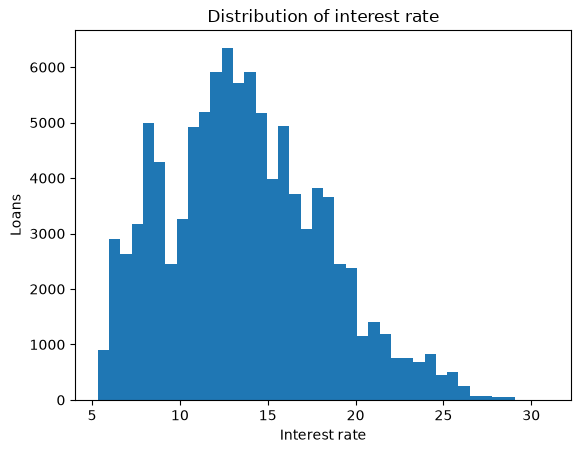


Interest rate by grade:
  A  mean =  7.39  |  median =  7.62  |  n = 15,905
  B  mean = 11.23  |  median = 11.14  |  n = 29,371
  C  mean = 14.32  |  median = 14.31  |  n = 26,899
  D  mean = 17.50  |  median = 17.57  |  n = 16,066
  E  mean = 20.28  |  median = 20.49  |  n = 7,964
  F  mean = 23.69  |  median = 23.83  |  n = 2,975
  G  mean = 25.85  |  median = 25.83  |  n = 820


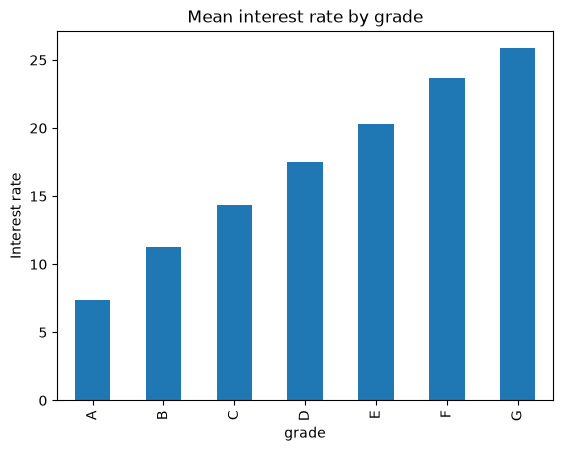


Interest rate by term (months):
  36 months  mean = 12.58  |  median = 12.49  |  n = 76,155
  60 months  mean = 17.13  |  median = 16.99  |  n = 23,845

One-way ANOVA of int_rate across grade:
  F = 169114.5  |  p-value = 0
  Groups: ['A', 'B', 'C', 'D', 'E', 'F', 'G']

Pearson correlation with int_rate:
  term                    r =  0.433
  revol_util              r =  0.294
  dti                     r =  0.176
  loan_amnt               r =  0.173
  mort_acc                r = -0.071
  pub_rec                 r =  0.066
  pub_rec_bankruptcies    r =  0.057
  annual_inc              r = -0.054
  total_acc               r = -0.040
  emp_length              r =  0.015
  open_acc                r =  0.011
  revol_bal               r = -0.011


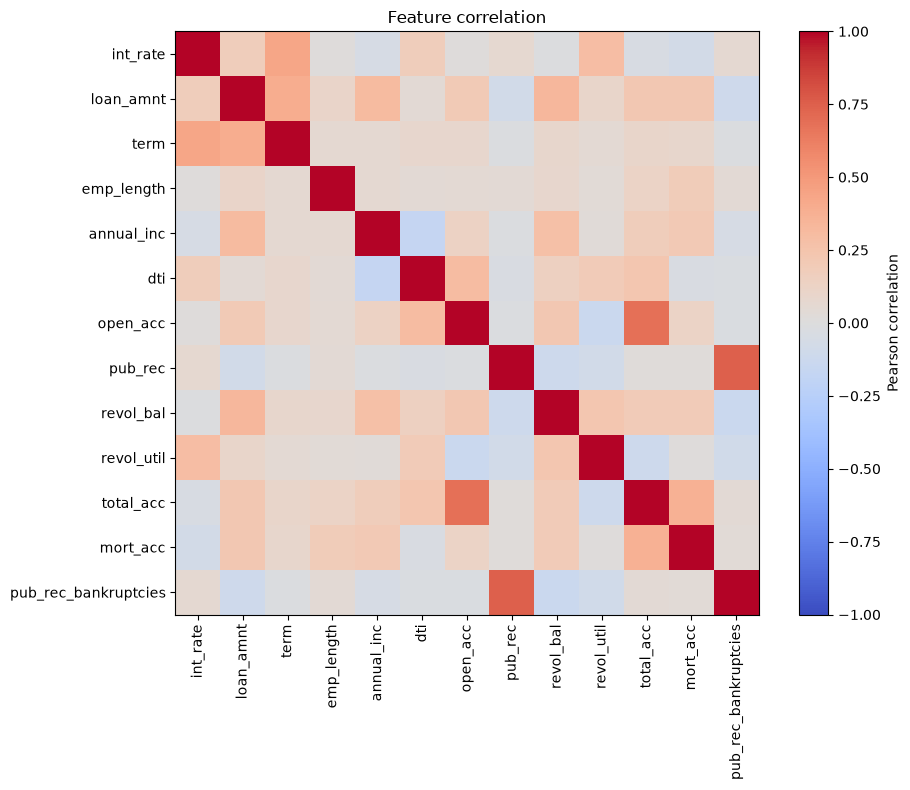

In [4]:
import matplotlib.pyplot as plt
from scipy import stats

print("Interest rate in the sample:")
print(f"  mean   : {df['int_rate'].mean():.2f}")
print(f"  median : {df['int_rate'].median():.2f}")
print(f"  min    : {df['int_rate'].min():.2f}")
print(f"  max    : {df['int_rate'].max():.2f}")
print(f"  std    : {df['int_rate'].std():.2f}")

plt.hist(df['int_rate'], bins=40)
plt.xlabel('Interest rate')
plt.ylabel('Loans')
plt.title('Distribution of interest rate')
plt.show()

print("\nInterest rate by grade:")
grade_order = sorted(df['grade'].unique())
for g in grade_order:
    grp = df.loc[df['grade'] == g, 'int_rate']
    print(f"  {g}  mean = {grp.mean():5.2f}  |  median = {grp.median():5.2f}  |  n = {len(grp):,}")

df.groupby('grade')['int_rate'].mean().reindex(grade_order).plot(
    kind='bar', title='Mean interest rate by grade')
plt.ylabel('Interest rate')
plt.show()

print("\nInterest rate by term (months):")
for t, grp in df.groupby('term')['int_rate']:
    print(f"  {t} months  mean = {grp.mean():5.2f}  |  median = {grp.median():5.2f}  |  n = {len(grp):,}")

# One-way ANOVA: does mean int_rate differ across grade?
groups = [df.loc[df['grade'] == g, 'int_rate'] for g in grade_order]
f_stat, p_anova = stats.f_oneway(*groups)
print(f"\nOne-way ANOVA of int_rate across grade:")
print(f"  F = {f_stat:.1f}  |  p-value = {p_anova:.4g}")
print(f"  Groups: {grade_order}")

num_cols = [
    'int_rate', 'loan_amnt', 'term', 'emp_length', 'annual_inc', 'dti',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
    'mort_acc', 'pub_rec_bankruptcies',
]
print("\nPearson correlation with int_rate:")
corrs = df[num_cols].corr()['int_rate'].drop('int_rate').sort_values(key=abs, ascending=False)
for col, r in corrs.items():
    print(f"  {col:22s}  r = {r:6.3f}")

corr = df[num_cols].corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Pearson correlation')
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.title('Feature correlation')
plt.tight_layout()
plt.show()

**Findings**
- Sample interest rate: mean 13.67, median 13.33, min 5.32, max 30.99, standard deviation 4.47.
- Mean rate by grade rises steadily: A 7.39 (n = 15,905), B 11.23 (29,371), C 14.32 (26,899), D 17.50 (16,066), E 20.28 (7,964), F 23.69 (2,975) and G 25.85 (820). One-way ANOVA of rate across grade: F = 169,114.5, p-value = 0.
- 36-month loans have a mean rate of 12.58 (n = 76,155); 60-month loans have a mean rate of 17.13 (n = 23,845).
- Strongest Pearson correlations with the rate: term 0.433, `revol_util` 0.294, `dti` 0.176 and `loan_amnt` 0.173.
- **How to read this:** a steady rise in the mean rate from A to G, plus a very small ANOVA p-value, is the sign that grade already is the price bucket. The next step drops it.

## Step 4: Drop `grade`, `sub_grade` and `installment` (leakage)
**What we do**
- Drop `grade` and `sub_grade`. They are Lending Club's risk rating, and the posted rate follows that rating closely, so they are the price decision itself.
- Drop `installment`. The monthly payment is computed from the loan amount, the term and the interest rate, so it would leak the target.
- Also drop free-text and post-origination fields we will not use: `emp_title`, `title`, `address`, `loan_status`, `issue_d`, `earliest_cr_line` and `initial_list_status`.

**Why it matters**
- If we left grade in, the model would mostly recover the rate card, and the other application features would look weaker than they are.
- If we left installment in, the model could back out the rate from the payment, the amount and the term. That would look accurate and be useless for pricing.
- This is the same idea as dropping call `duration` in a propensity model: the feature is only known with, or because of, the answer.

**Domain link**
- A pricing model should be allowed to use only information known at application time, and should not be handed the rating that already set the price.
- The same rule holds at an NBFC: an internal risk grade or an LTV band that already produced the rate should stay out of a model whose job is to support that rate.
- At an NBFC like Muthoot, that internal grade should stay out of the rate model.
- JD-based: "data preparation" and honest model design. Domain-based: no leakage from the price decision back into the pricing model.

**Interview line**
- "I dropped grade and sub-grade because they are the price decision, and I dropped installment because it is computed from the rate. Leaving them in would inflate the scores and would not be a fair pricing model." 

In [5]:
print("Mean installment by grade (shown only to illustrate the leak, then dropped):")
for g in sorted(df['grade'].unique()):
    grp = df.loc[df['grade'] == g]
    print(
        f"  {g}  mean rate = {grp['int_rate'].mean():5.2f}  |  "
        f"mean installment = {grp['installment'].mean():7.2f}  |  n = {len(grp):,}"
    )

leak_cols = ['grade', 'sub_grade', 'installment']
unused_cols = [
    'emp_title', 'title', 'address', 'loan_status',
    'issue_d', 'earliest_cr_line', 'initial_list_status',
]
df = df.drop(columns=leak_cols + unused_cols)

print("\nDropped leakage columns : grade, sub_grade, installment")
print("Dropped unused columns  : emp_title, title, address, loan_status, issue_d, earliest_cr_line, initial_list_status")
print("\nRemaining columns:")
print(list(df.columns))
print(f"Rows x columns: {df.shape[0]:,} x {df.shape[1]}")

Mean installment by grade (shown only to illustrate the leak, then dropped):
  A  mean rate =  7.39  |  mean installment =  407.03  |  n = 15,905
  B  mean rate = 11.23  |  mean installment =  403.76  |  n = 29,371
  C  mean rate = 14.32  |  mean installment =  417.77  |  n = 26,899
  D  mean rate = 17.50  |  mean installment =  451.26  |  n = 16,066
  E  mean rate = 20.28  |  mean installment =  521.10  |  n = 7,964
  F  mean rate = 23.69  |  mean installment =  577.66  |  n = 2,975
  G  mean rate = 25.85  |  mean installment =  655.32  |  n = 820

Dropped leakage columns : grade, sub_grade, installment
Dropped unused columns  : emp_title, title, address, loan_status, issue_d, earliest_cr_line, initial_list_status

Remaining columns:
['loan_amnt', 'term', 'int_rate', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'application_type', 'mort_acc', 'pub_rec_bankruptcies']
Rows x columns:

**Findings**
- `grade`, `sub_grade` and `installment` were dropped as leakage, along with the unused text and post-origination fields. The table is then 100,000 rows by 17 columns.
- **How to read this:** the model will now see only application and loan-term fields, not the rating or the payment that already contains the rate.

## Step 5: One-hot Encoding
**What we do**
- One-hot encode the remaining categorical fields: `home_ownership`, `verification_status`, `purpose` and `application_type`, with `drop_first=True`.
- Leave the numeric fields, including the parsed `term` and `emp_length`, as they are.

**Why it matters**
- Linear regression and Ridge need numbers. A one-hot column is a simple 0/1 flag for each category (minus one, to avoid a redundant column).
- Tree models can split on these 0/1 flags as well, so all five models can share the same feature matrix.

**Domain link**
- Home ownership, loan purpose and income verification are standard pricing and underwriting fields: a mortgage vs rent, or a small-business purpose vs a credit-card refinance, can move risk and therefore the rate.
- JD-based: "data preparation". Domain-based: turning application categories into model features.

**Interview line**
- "I one-hot encoded home ownership, verification status, purpose and application type, and I kept term and employment length as numbers because I had already parsed them." 

In [6]:
cat_cols = ['home_ownership', 'verification_status', 'purpose', 'application_type']
num_cols = [c for c in df.columns if c not in cat_cols + ['int_rate']]

print("Categorical columns (will be one-hot encoded):")
print(cat_cols)
print("\nNumeric columns (kept as they are):")
print(num_cols)

for col in cat_cols:
    print(f"\n{col} value counts:")
    print(df[col].value_counts())

df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print(f"\nAfter one-hot encoding: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Feature columns (excluding int_rate): {df.shape[1] - 1}")
print("\nA few of the new dummy column names:")
dummy_cols = [c for c in df.columns if c not in num_cols + ['int_rate']]
print(dummy_cols)

Categorical columns (will be one-hot encoded):
['home_ownership', 'verification_status', 'purpose', 'application_type']

Numeric columns (kept as they are):
['loan_amnt', 'term', 'emp_length', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies']

home_ownership value counts:
home_ownership
MORTGAGE    50262
RENT        40281
OWN          9416
OTHER          27
NONE           14
Name: count, dtype: int64

verification_status value counts:
verification_status
Verified           35506
Source Verified    33078
Not Verified       31416
Name: count, dtype: int64

purpose value counts:
purpose
debt_consolidation    59265
credit_card           21007
home_improvement       6018
other                  5399
major_purchase         2151
small_business         1460
car                    1197
medical                1071
moving                  687
vacation                579
house                   535
wedding                 473
ren

**Findings**
- After one-hot encoding `home_ownership`, `verification_status`, `purpose` and `application_type`, the table is 100,000 rows by 34 columns, which is 33 feature columns plus the target.
- **How to read this:** one-hot encoding was applied on the full sample before the split, which is simple. In production the encoder should be fitted on the training set only.

## Step 6: Train / Validation / Test Split and Scaling
**What we do**
- Split the sample into train, validation and test sets (60% / 20% / 20%) with `random_state=42`. This is a regression problem, so we do not stratify.
- Fit `StandardScaler` on the training set only, then transform validation and test.
- Linear regression and Ridge will use the scaled features. Random Forest and XGBoost will use the unscaled features.

**Why it matters**
- The test set is the final report card. The validation set is what we use to pick the winner, so we do not choose a model by peeking at the test scores.
- The scaler must be fitted on train only. Using the test mean or standard deviation would be leakage.
- Linear models care about scale (`annual_inc` in tens of thousands vs `dti` around the teens). Tree splits do not, so the tree models can use the raw features.

**Domain link**
- A pricing model should be judged on loans it has not already seen, just as a credit team would test a rate card on a later book, not on the loans used to build it.
- JD-based: honest validation in the ML lifecycle. Domain-based: hold out a later-looking sample before you trust a rate model.

**Interview line**
- "I used a 60/20/20 split, fitted the scaler on train only, and reserved the validation set to pick the winner so the test set stayed a clean report card." 

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['int_rate'])
y = df['int_rate']

# 20% test first, then 25% of the remainder as validation, so the split is 60 / 20 / 20
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42)

X_train = X_train.copy()
X_valid = X_valid.copy()
X_test = X_test.copy()

# Scaled copy for linear regression and Ridge; tree models use X_train / X_valid / X_test
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

print("Split sizes and mean interest rate:")
for name, yy in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]:
    print(f"  {name:12s} rows = {len(yy):,} |  mean rate = {yy.mean():.2f}  |  std = {yy.std():.2f}")

print(f"\nFeatures used: {X_train.shape[1]}")
print("Linear regression and Ridge will use the scaled features (training-set mean and standard deviation only).")
print("Random Forest and XGBoost will use the unscaled features.")

Split sizes and mean interest rate:
  Train        rows = 60,000 |  mean rate = 13.65  |  std = 4.47
  Validation   rows = 20,000 |  mean rate = 13.73  |  std = 4.45
  Test         rows = 20,000 |  mean rate = 13.68  |  std = 4.48

Features used: 33
Linear regression and Ridge will use the scaled features (training-set mean and standard deviation only).
Random Forest and XGBoost will use the unscaled features.


**Findings**
- Train has 60,000 rows (mean rate 13.65), validation has 20,000 (mean rate 13.73) and test has 20,000 (mean rate 13.68). All three use 33 features.
- **How to read this:** the three mean rates should be close. If they were far apart, the split would be a poor comparison base.

## Step 7: Mean Baseline
**What we do**
- Predict the training-set mean interest rate for every loan in validation and test.
- Report MAE, RMSE and R² on the test set. R² of a mean baseline is about 0 by design.

**Why it matters**
- This is the simplest possible model: "charge everyone the average rate". Every later model should beat it on MAE and RMSE.
- MAE here is also a useful business number: how many rate points you would be off if you ignored the applicant's profile.

**Domain link**
- A single book-level rate is the opposite of risk-based pricing. The gap between this baseline and a real model is the value of using applicant and loan features.
- JD-based: a baseline before the named regression and tree models. Domain-based: a flat rate vs a priced rate.

**Interview line**
- "I started with a mean baseline: predict the average training rate for every loan. That is the flat-rate policy, and every later model has to beat it." 

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mean_rate = y_train.mean()
base_valid_pred = np.full(len(y_valid), mean_rate)
base_test_pred = np.full(len(y_test), mean_rate)

base_mae = mean_absolute_error(y_test, base_test_pred)
base_rmse = np.sqrt(mean_squared_error(y_test, base_test_pred))
base_r2 = r2_score(y_test, base_test_pred)

print(f"Training-set mean rate used as the prediction: {mean_rate:.4f}")
print(f"Mean baseline  - MAE: {base_mae:.4f}  |  RMSE: {base_rmse:.4f}  |  R2: {base_r2:.4f}")
print("R2 is about 0 because the baseline predicts the mean.")

Training-set mean rate used as the prediction: 13.6455
Mean baseline  - MAE: 3.5812  |  RMSE: 4.4793  |  R2: -0.0000
R2 is about 0 because the baseline predicts the mean.


**Findings**
- The training-set mean rate used as the prediction is 13.6455. On the test set the mean baseline scores MAE 3.5812, RMSE 4.4793 and R² 0.0000.
- **How to read this:** MAE is in interest-rate points. Later models should have a lower MAE and RMSE, and an R² above 0.

## Step 8: Linear Regression
**What we do**
- Fit ordinary least squares on the scaled training features.
- Predict on validation and test, and report test MAE, RMSE and R² next to the mean baseline.
- Print the largest coefficients (features are on a comparable scale after Step 6).

**Why it matters**
- Linear regression is the simplest model that actually uses the applicant's profile. It is also easy to explain: a positive coefficient raises the predicted rate.
- It is the first regression method to show, and it is the baseline that Ridge, Random Forest and XGBoost have to beat.

**Domain link**
- A credit head can read a coefficient as "holding the other fields fixed, this feature moves the rate up or down". Term, utilisation and DTI are the kinds of signs we expect to be positive (higher risk, higher rate).
- JD-based: "regression" and Scikit-learn. Domain-based: a transparent first pricing model.

**Interview line**
- "Linear regression was my first real model, fitted on scaled features so the coefficients are comparable. I used it as a clear, explainable baseline for the tree models." 

In [9]:
from sklearn.linear_model import LinearRegression

lin_model = LinearRegression()
lin_model.fit(X_train_scaled, y_train)

lin_valid_pred = lin_model.predict(X_valid_scaled)
lin_test_pred = lin_model.predict(X_test_scaled)

lin_mae = mean_absolute_error(y_test, lin_test_pred)
lin_rmse = np.sqrt(mean_squared_error(y_test, lin_test_pred))
lin_r2 = r2_score(y_test, lin_test_pred)

print(f"Mean baseline       - MAE: {base_mae:.4f}  |  RMSE: {base_rmse:.4f}  |  R2: {base_r2:.4f}")
print(f"Linear regression   - MAE: {lin_mae:.4f}  |  RMSE: {lin_rmse:.4f}  |  R2: {lin_r2:.4f}")

coefs = pd.Series(lin_model.coef_, index=X_train.columns)
top10 = coefs.abs().sort_values(ascending=False).head(10).index
print("\nTop 10 linear coefficients (positive raises the predicted rate):")
for f in top10:
    print(f"  {f:30s}  coef = {coefs[f]:7.3f}")

Mean baseline       - MAE: 3.5812  |  RMSE: 4.4793  |  R2: -0.0000
Linear regression   - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785

Top 10 linear coefficients (positive raises the predicted rate):
  term                            coef =   1.747
  revol_util                      coef =   1.382
  purpose_other                   coef =   0.669
  verification_status_Verified    coef =   0.649
  revol_bal                       coef =  -0.468
  open_acc                        coef =   0.449
  total_acc                       coef =  -0.417
  home_ownership_RENT             coef =   0.366
  purpose_small_business          coef =   0.365
  dti                             coef =   0.364


**Findings**
- Linear regression scores test MAE 2.8192, RMSE 3.5313 and R² 0.3785, a clear improvement on the mean baseline (MAE 3.5812, RMSE 4.4793, R² 0.0000).
- The largest coefficients (positive raises the predicted rate) are term 1.747, `revol_util` 1.382, `purpose_other` 0.669, `verification_status_Verified` 0.649, `revol_bal` -0.468, `open_acc` 0.449, `total_acc` -0.417, `home_ownership_RENT` 0.366, `purpose_small_business` 0.365 and `dti` 0.364.
- **How to read this:** a lower MAE than the mean baseline means the applicant and loan features already add pricing signal, even without grade.

## Step 9: Ridge
**What we do**
- Fit Ridge (linear regression with an L2 penalty, `alpha=1.0`) on the same scaled features.
- Report test MAE, RMSE and R² next to the mean baseline and ordinary linear regression.

**Why it matters**
- One-hot features and correlated credit fields (for example open accounts and total accounts) can make ordinary least squares coefficients unstable.
- Ridge shrinks large coefficients and is a standard next step after linear regression. If the two scores are almost the same, the collinearity is not severe at this alpha.

**Domain link**
- Pricing features often move together (income and loan amount, utilisation and revolving balance). A slightly penalised linear model is a safer default than unpenalised least squares when you still want a transparent rate equation.
- JD-based: "regression" and Scikit-learn. Domain-based: a more stable linear pricing model.

**Interview line**
- "I added Ridge as a regularised linear model. If its scores are close to ordinary least squares, that tells me collinearity is not a big problem at this penalty; I still prefer to have the regularised version on the table." 

In [10]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

ridge_valid_pred = ridge_model.predict(X_valid_scaled)
ridge_test_pred = ridge_model.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, ridge_test_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))
ridge_r2 = r2_score(y_test, ridge_test_pred)

print(f"Mean baseline       - MAE: {base_mae:.4f}  |  RMSE: {base_rmse:.4f}  |  R2: {base_r2:.4f}")
print(f"Linear regression   - MAE: {lin_mae:.4f}  |  RMSE: {lin_rmse:.4f}  |  R2: {lin_r2:.4f}")
print(f"Ridge               - MAE: {ridge_mae:.4f}  |  RMSE: {ridge_rmse:.4f}  |  R2: {ridge_r2:.4f}")

ridge_coefs = pd.Series(ridge_model.coef_, index=X_train.columns)
top10 = ridge_coefs.abs().sort_values(ascending=False).head(10).index
print("\nTop 10 Ridge coefficients (positive raises the predicted rate):")
for f in top10:
    print(f"  {f:30s}  coef = {ridge_coefs[f]:7.3f}")

Mean baseline       - MAE: 3.5812  |  RMSE: 4.4793  |  R2: -0.0000
Linear regression   - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785
Ridge               - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785

Top 10 Ridge coefficients (positive raises the predicted rate):
  term                            coef =   1.747
  revol_util                      coef =   1.382
  purpose_other                   coef =   0.668
  verification_status_Verified    coef =   0.649
  revol_bal                       coef =  -0.468
  open_acc                        coef =   0.449
  total_acc                       coef =  -0.417
  home_ownership_RENT             coef =   0.366
  purpose_small_business          coef =   0.365
  dti                             coef =   0.364


**Findings**
- Ridge scores test MAE 2.8192, RMSE 3.5313 and R² 0.3785, the same as ordinary linear regression at alpha = 1.
- **How to read this:** if Ridge and linear regression are almost the same, the L2 penalty is not changing the fit much at alpha = 1. The value is still having a regularised linear model to compare with the trees.

## Step 10: Random Forest
**What we do**
- Fit a Random Forest regressor on the unscaled training features (`n_estimators=100`, `max_depth=12`, `min_samples_leaf=5`).
- Report test MAE, RMSE and R² next to the linear models.

**Why it matters**
- A forest can capture non-linear effects and interactions (for example a long term combined with high utilisation) that a straight line misses.
- Capping the depth and the leaf size keeps the trees from memorising the training sample, and keeps the CPU run short.

**Domain link**
- Pricing is rarely a pure straight line: the extra rate for a 60-month term may be larger in a more stretched DTI band than in a comfortable one. A tree ensemble can learn that shape.
- JD-based: "tree-based models" and Scikit-learn. Domain-based: non-linear risk-based pricing.

**Interview line**
- "Random Forest was my first tree ensemble: it can pick up interactions that a linear rate equation misses, and I capped the depth so it would not just memorise the training loans." 

In [11]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train, y_train)

rf_valid_pred = rf_model.predict(X_valid)
rf_test_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_test_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_test_pred))
rf_r2 = r2_score(y_test, rf_test_pred)

print(f"Mean baseline       - MAE: {base_mae:.4f}  |  RMSE: {base_rmse:.4f}  |  R2: {base_r2:.4f}")
print(f"Linear regression   - MAE: {lin_mae:.4f}  |  RMSE: {lin_rmse:.4f}  |  R2: {lin_r2:.4f}")
print(f"Ridge               - MAE: {ridge_mae:.4f}  |  RMSE: {ridge_rmse:.4f}  |  R2: {ridge_r2:.4f}")
print(f"Random Forest       - MAE: {rf_mae:.4f}  |  RMSE: {rf_rmse:.4f}  |  R2: {rf_r2:.4f}")

Mean baseline       - MAE: 3.5812  |  RMSE: 4.4793  |  R2: -0.0000
Linear regression   - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785
Ridge               - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785
Random Forest       - MAE: 2.6917  |  RMSE: 3.3906  |  R2: 0.4270


**Findings**
- Random Forest scores test MAE 2.6917, RMSE 3.3906 and R² 0.4270, a clear gain over the linear models (RMSE 3.5313, R² 0.3785).
- **How to read this:** a clear gain over linear regression means non-linear effects or interactions are adding pricing signal.

## Step 11: XGBoost Model
**What we do**
- Fit an XGBoost regressor on the unscaled training features, with early stopping on the validation set (`eval_metric='rmse'`).
- Report test MAE, RMSE and R² next to the other models, and print the number of trees chosen by early stopping.

**Why it matters**
- Boosting builds trees in sequence, each one correcting the remaining rate errors. It is often the strongest tabular model in this kind of comparison.
- Early stopping uses the validation set to halt extra trees, which reduces over-fitting and keeps the run short.

**Domain link**
- Once a linear model and a forest are on the table, boosting is the usual next step for a pricing or credit model that has to capture a mix of linear and non-linear effects.
- JD-based: "boosting" and XGBoost. Domain-based: a strong candidate for a production rate model.

**Interview line**
- "XGBoost was the boosting model: I used early stopping on the validation RMSE so the number of trees was chosen without looking at the test set." 

In [12]:
import xgboost as xgb

xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='rmse',
    early_stopping_rounds=40,
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)

xgb_valid_pred = xgb_model.predict(X_valid)
xgb_test_pred = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_test_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_test_pred))
xgb_r2 = r2_score(y_test, xgb_test_pred)

print(f"Best number of trees: {xgb_model.best_iteration}")
print(f"Mean baseline       - MAE: {base_mae:.4f}  |  RMSE: {base_rmse:.4f}  |  R2: {base_r2:.4f}")
print(f"Linear regression   - MAE: {lin_mae:.4f}  |  RMSE: {lin_rmse:.4f}  |  R2: {lin_r2:.4f}")
print(f"Ridge               - MAE: {ridge_mae:.4f}  |  RMSE: {ridge_rmse:.4f}  |  R2: {ridge_r2:.4f}")
print(f"Random Forest       - MAE: {rf_mae:.4f}  |  RMSE: {rf_rmse:.4f}  |  R2: {rf_r2:.4f}")
print(f"XGBoost             - MAE: {xgb_mae:.4f}  |  RMSE: {xgb_rmse:.4f}  |  R2: {xgb_r2:.4f}")

Best number of trees: 299
Mean baseline       - MAE: 3.5812  |  RMSE: 4.4793  |  R2: -0.0000
Linear regression   - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785
Ridge               - MAE: 2.8192  |  RMSE: 3.5313  |  R2: 0.3785
Random Forest       - MAE: 2.6917  |  RMSE: 3.3906  |  R2: 0.4270
XGBoost             - MAE: 2.5929  |  RMSE: 3.2711  |  R2: 0.4667


**Findings**
- Early stopping chose 299 trees. XGBoost scores test MAE 2.5929, RMSE 3.2711 and R² 0.4667, the best of the five models on the test set.
- **How to read this:** the number of trees is chosen on the validation set. The test scores are the ones to quote.

## Step 12: Compare Models, Actual vs Predicted, and Residuals
**What we do**
- Put the test MAE, RMSE and R² of all five models in one printed list, and draw a simple bar chart of test RMSE.
- Pick the winner by validation RMSE (lower is better), not by the test set.
- For the winner, plot actual vs predicted, residuals vs predicted, and a residual histogram on the test set.

**Why it matters**
- MAE is the number a business head can hear ("off by about X rate points"). RMSE penalises large misses more. R² says how much of the rate variation we explain.
- The residual plots show whether errors are centred on zero, and whether the model struggles at high or low rates.
- Choosing the winner on validation keeps the test set honest.

**Stats used:** MAE, RMSE, R², residual plots.

**Domain link**
- For a pricing team, a model that is usually close but badly off on a few high-rate loans is more dangerous than the same average error spread evenly. That is why we look at RMSE and the residual plots, not only MAE.
- JD-based: model evaluation in the ML lifecycle. Domain-based: judging a rate model on error size and on where it misses.

**Interview line**
- "I compared the five models on MAE, RMSE and R², picked the winner on validation RMSE, and then checked actual-vs-predicted and residual plots on the test set." 

Model                 Test MAE  Test RMSE  Test R2
Mean baseline           3.5812     4.4793  -0.0000
Linear regression       2.8192     3.5313   0.3785
Ridge                   2.8192     3.5313   0.3785
Random Forest           2.6917     3.3906   0.4270
XGBoost                 2.5929     3.2711   0.4667

Best model by validation RMSE: XGBoost  (3.2645)
Test MAE  : 2.5929
Test RMSE : 3.2711
Test R2   : 0.4667


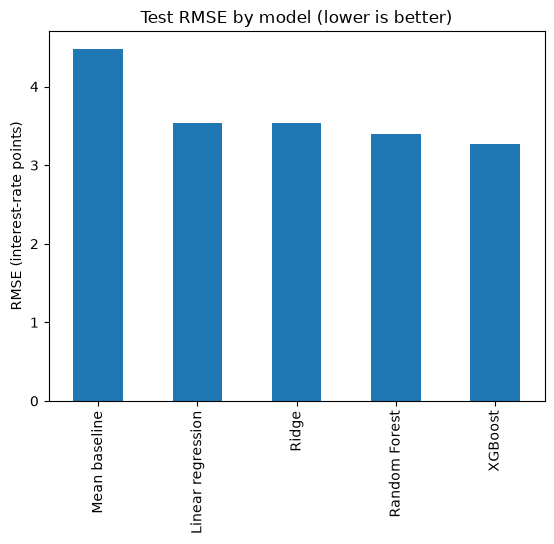

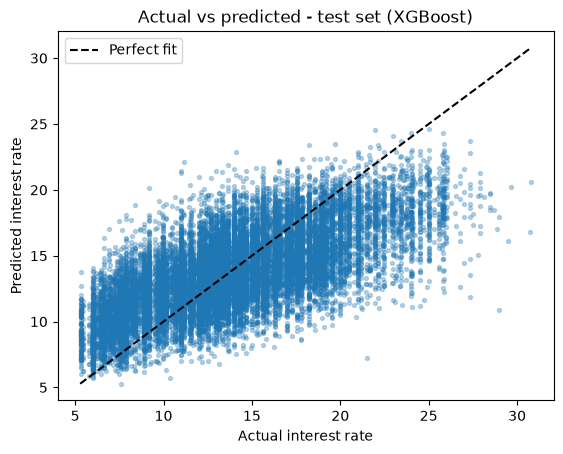


Residual summary (actual - predicted) for XGBoost:
  mean   : 0.0171
  median : -0.2306
  std    : 3.2711
  min    : -10.9985
  max    : 18.0738


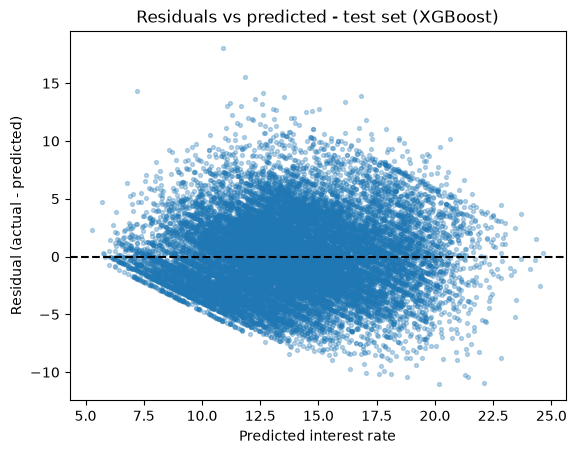

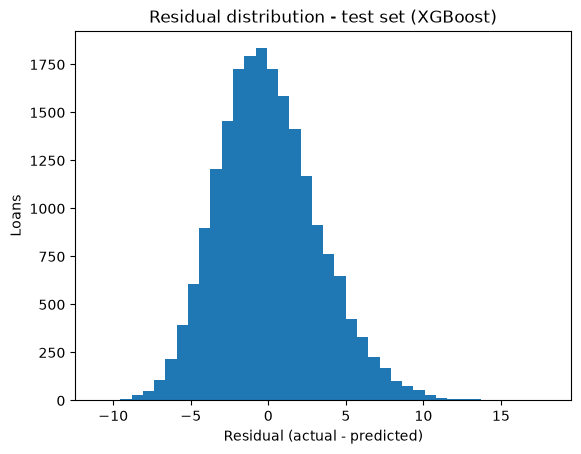

In [13]:
models = {
    'Mean baseline': (base_valid_pred, base_test_pred),
    'Linear regression': (lin_valid_pred, lin_test_pred),
    'Ridge': (ridge_valid_pred, ridge_test_pred),
    'Random Forest': (rf_valid_pred, rf_test_pred),
    'XGBoost': (xgb_valid_pred, xgb_test_pred),
}

print(f"{'Model':20s}  Test MAE  Test RMSE  Test R2")
for name, (v_pred, t_pred) in models.items():
    mae = mean_absolute_error(y_test, t_pred)
    rmse = np.sqrt(mean_squared_error(y_test, t_pred))
    r2 = r2_score(y_test, t_pred)
    print(f"{name:20s}  {mae:8.4f}  {rmse:9.4f}  {r2:7.4f}")

# Winner by validation RMSE, not by the test set
valid_rmse = {
    name: np.sqrt(mean_squared_error(y_valid, v_pred))
    for name, (v_pred, t_pred) in models.items()
}
best_name = min(valid_rmse, key=valid_rmse.get)
best_test_pred = models[best_name][1]
print(f"\nBest model by validation RMSE: {best_name}  ({valid_rmse[best_name]:.4f})")
print(f"Test MAE  : {mean_absolute_error(y_test, best_test_pred):.4f}")
print(f"Test RMSE : {np.sqrt(mean_squared_error(y_test, best_test_pred)):.4f}")
print(f"Test R2   : {r2_score(y_test, best_test_pred):.4f}")

rmse_bars = pd.Series(
    {name: np.sqrt(mean_squared_error(y_test, t_pred)) for name, (v_pred, t_pred) in models.items()}
)
rmse_bars.plot(kind='bar', title='Test RMSE by model (lower is better)')
plt.ylabel('RMSE (interest-rate points)')
plt.show()

# Actual vs predicted for the winner
plt.scatter(y_test, best_test_pred, s=8, alpha=0.3)
lims = [min(y_test.min(), best_test_pred.min()), max(y_test.max(), best_test_pred.max())]
plt.plot(lims, lims, 'k--', label='Perfect fit')
plt.xlabel('Actual interest rate')
plt.ylabel('Predicted interest rate')
plt.title(f'Actual vs predicted - test set ({best_name})')
plt.legend()
plt.show()

resid = y_test - best_test_pred
print(f"\nResidual summary (actual - predicted) for {best_name}:")
print(f"  mean   : {resid.mean():.4f}")
print(f"  median : {resid.median():.4f}")
print(f"  std    : {resid.std():.4f}")
print(f"  min    : {resid.min():.4f}")
print(f"  max    : {resid.max():.4f}")

plt.scatter(best_test_pred, resid, s=8, alpha=0.3)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Predicted interest rate')
plt.ylabel('Residual (actual - predicted)')
plt.title(f'Residuals vs predicted - test set ({best_name})')
plt.show()

plt.hist(resid, bins=40)
plt.xlabel('Residual (actual - predicted)')
plt.ylabel('Loans')
plt.title(f'Residual distribution - test set ({best_name})')
plt.show()

**Findings**
- Test scores: mean baseline MAE 3.5812, RMSE 4.4793, R² 0.0000; linear regression and Ridge MAE 2.8192, RMSE 3.5313, R² 0.3785; Random Forest MAE 2.6917, RMSE 3.3906, R² 0.4270; XGBoost MAE 2.5929, RMSE 3.2711, R² 0.4667.
- The winner by validation RMSE is XGBoost (3.2645). Its test MAE is 2.5929, RMSE 3.2711 and R² 0.4667.
- Residuals (actual minus predicted) have mean 0.0171, median -0.2306, standard deviation 3.2711, min -10.9985 and max 18.0738.
- **How to read this:** a residual mean near zero is good. A fan shape (errors growing at higher predicted rates) would mean the model is less reliable on more expensive loans.

## Step 13: Feature Importance and SHAP
**What we do**
- Print and plot the top 15 features by Random Forest importance and by XGBoost gain.
- Compute SHAP values for XGBoost on a 2,000-row sample of the test set, and draw a SHAP summary plot.
- Print the top reasons for one high-rate prediction in that sample.

**Why it matters**
- Feature importance says which fields the model relied on overall. SHAP says how those fields pushed a single loan's predicted rate up or down.
- After we drop grade, we want to see whether the remaining drivers look like real pricing signals (term, utilisation, DTI, income) rather than an accidental proxy for the rating.

**Domain link**
- A pricing or credit head will ask why one applicant is shown a higher rate than another. SHAP gives a short reason list in the same units as the prediction (rate points).
- The same explanation step would be used when a branch or a customer asks why a personal-loan or gold-loan rate came out higher.
- At an NBFC like Muthoot, that conversation would often be about a gold-loan rate.
- JD-based: model explanation. Domain-based: explaining a risk-based rate.

**Interview line**
- "I used Random Forest and XGBoost importance for the overall drivers, and SHAP to explain one loan's predicted rate in rate points." 

Top 15 features by Random Forest importance:
  term                            33.09
  revol_util                      18.24
  revol_bal                       7.98
  annual_inc                      5.65
  loan_amnt                       5.52
  mort_acc                        5.22
  dti                             4.61
  open_acc                        3.34
  purpose_credit_card             3.27
  verification_status_Verified    2.88
  total_acc                       2.42
  pub_rec                         2.21
  emp_length                      1.36
  purpose_debt_consolidation      1.14
  purpose_other                   1.05

Top 15 features by XGBoost gain importance (% of total gain):
  term                            59.05
  purpose_credit_card             4.67
  verification_status_Verified    4.30
  revol_util                      3.45
  pub_rec                         2.82
  purpose_other                   2.65
  verification_status_Source Verified  2.60
  purpose_debt_consolidati

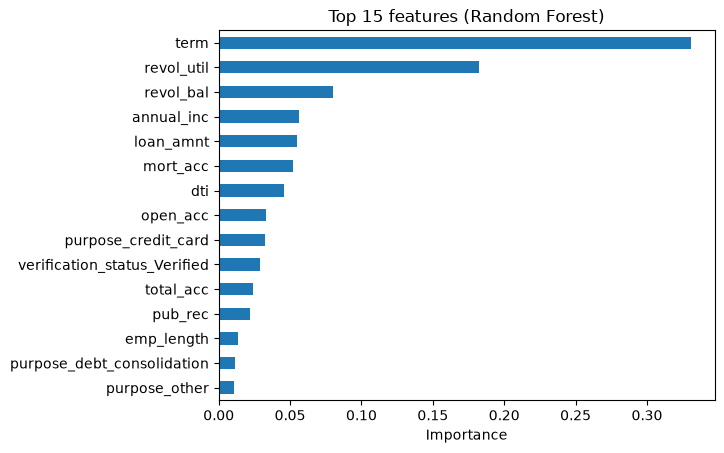

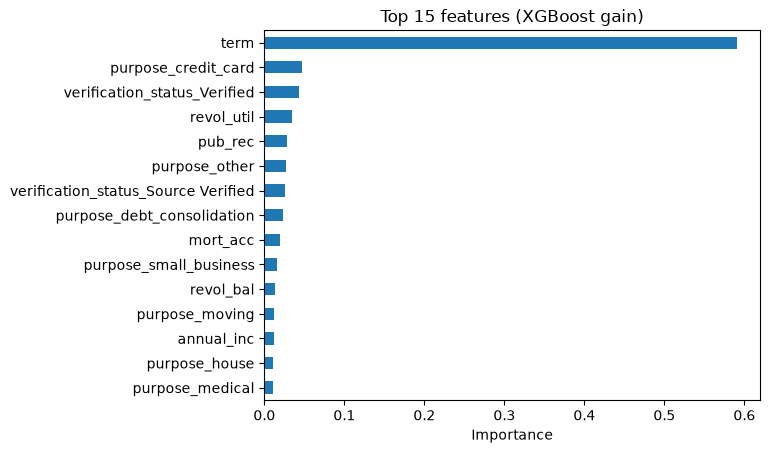

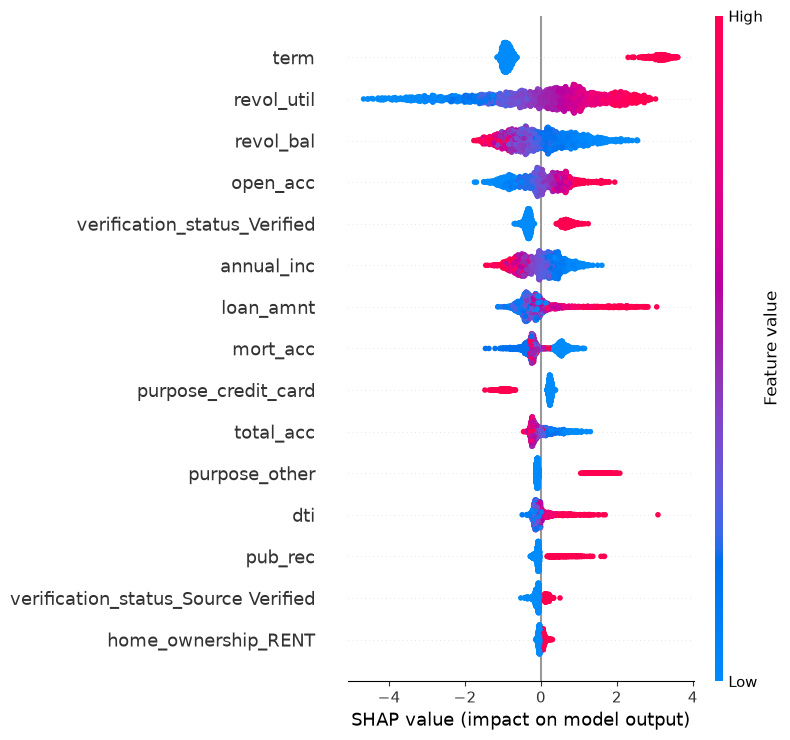


Sample loan (row index 59907)
Predicted rate: 24.3238
Top 5 reasons pushing the predicted rate UP:
  term                            value = 60.000  |  SHAP = +3.165
  revol_bal                       value = 722.000  |  SHAP = +1.730
  purpose_other                   value = 1.000  |  SHAP = +1.668
  revol_util                      value = 90.200  |  SHAP = +1.500
  mort_acc                        value = 0.000  |  SHAP = +0.883
Top 3 factors pulling the predicted rate DOWN:
  verification_status_Source Verified  value = 0.000  |  SHAP = -0.111
  dti                             value = 15.360  |  SHAP = -0.144
  open_acc                        value = 2.000  |  SHAP = -1.192


In [14]:
import shap

rf_imp = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
xgb_imp = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("Top 15 features by Random Forest importance:")
for f, v in (rf_imp.head(15) * 100).items():
    print(f"  {f:30s}  {v:.2f}")

print("\nTop 15 features by XGBoost gain importance (% of total gain):")
for f, v in (xgb_imp.head(15) * 100).items():
    print(f"  {f:30s}  {v:.2f}")

rf_imp.head(15).sort_values().plot(kind='barh', title='Top 15 features (Random Forest)')
plt.xlabel('Importance')
plt.show()

xgb_imp.head(15).sort_values().plot(kind='barh', title='Top 15 features (XGBoost gain)')
plt.xlabel('Importance')
plt.show()

# SHAP on 2,000 test loans, using XGBoost
shap_sample = X_test.sample(2000, random_state=42)
shap_values = shap.TreeExplainer(xgb_model).shap_values(shap_sample)
shap.summary_plot(shap_values, shap_sample, max_display=15)

# Reasons for the highest predicted rate in the sample
i = xgb_model.predict(shap_sample).argmax()
reasons = pd.Series(shap_values[i], index=shap_sample.columns).sort_values(ascending=False)
print(f"\nSample loan (row index {shap_sample.index[i]})")
print(f"Predicted rate: {xgb_model.predict(shap_sample)[i]:.4f}")
print("Top 5 reasons pushing the predicted rate UP:")
for f, v in reasons.head(5).items():
    print(f"  {f:30s}  value = {shap_sample.iloc[i][f]:.3f}  |  SHAP = {v:+.3f}")
print("Top 3 factors pulling the predicted rate DOWN:")
for f, v in reasons.tail(3).items():
    print(f"  {f:30s}  value = {shap_sample.iloc[i][f]:.3f}  |  SHAP = {v:+.3f}")

**Findings**
- Top Random Forest features: term 33.09%, `revol_util` 18.24%, `revol_bal` 7.98%, `annual_inc` 5.65% and `loan_amnt` 5.52%.
- Top XGBoost gain features: term 59.05%, `purpose_credit_card` 4.67%, `verification_status_Verified` 4.30%, `revol_util` 3.45% and `pub_rec` 2.82%.
- For the sample loan (row 59907) the predicted rate is 24.3238. The main reasons pushing the rate up are a 60-month term (SHAP +3.165), `revol_bal` 722 (+1.730), `purpose_other` (+1.668), `revol_util` 90.2 (+1.500) and `mort_acc` 0 (+0.883). `open_acc` 2 (SHAP -1.192), `dti` 15.36 and `verification_status_Source Verified` = 0 pulled the predicted rate down a little.
- **How to read this:** after grade is dropped, term, utilisation and DTI are the kinds of drivers you would expect in a risk-based price. A high-cardinality leftover or a post-origination field showing up here would be a warning.

## Step 14: MLflow Tracking
**What we do**
- Install MLflow, point it at a local `mlflow.db` file, and log one run per model with its parameters and test MAE, RMSE and R².

**Why it matters**
- Experiment tracking makes this run comparable with a later re-train, and keeps the five models side by side.
- The run id printed at the end is what you would look up if you needed to reload a logged model.

**Domain link**
- A pricing model is re-fitted when the book or the rate card changes. Logging the run is what makes that re-fit comparable with the current model.
- JD-based: tracking in the ML lifecycle. Domain-based: a repeatable rate-model run.

**Interview line**
- "I logged all five models in MLflow, with the test MAE, RMSE and R², so a later re-train can be compared with this run." 

In [15]:
!pip install -q mlflow
import mlflow

mlflow.set_tracking_uri('sqlite:///mlflow.db')      # local database file
mlflow.set_experiment('lending-club-interest-rate')

sk_models = {
    'linear_regression': (lin_model, lin_test_pred, 'sklearn'),
    'ridge': (ridge_model, ridge_test_pred, 'sklearn'),
    'random_forest': (rf_model, rf_test_pred, 'sklearn'),
    'xgboost': (xgb_model, xgb_test_pred, 'xgboost'),
}

with mlflow.start_run(run_name='mean_baseline'):
    mlflow.log_params({'model': 'mean_baseline'})
    mlflow.log_metric('mae', float(base_mae))
    mlflow.log_metric('rmse', float(base_rmse))
    mlflow.log_metric('r2', float(base_r2))
    print(f"MLflow run logged for mean_baseline: {mlflow.active_run().info.run_id}")

for name, (model, t_pred, flavour) in sk_models.items():
    with mlflow.start_run(run_name=name):
        mlflow.log_params({'model': name})
        if name == 'xgboost':
            mlflow.log_params({'best_iteration': int(xgb_model.best_iteration)})
        if name == 'ridge':
            mlflow.log_params({'alpha': 1.0})
        mlflow.log_metric('mae', float(mean_absolute_error(y_test, t_pred)))
        mlflow.log_metric('rmse', float(np.sqrt(mean_squared_error(y_test, t_pred))))
        mlflow.log_metric('r2', float(r2_score(y_test, t_pred)))
        if flavour == 'xgboost':
            mlflow.xgboost.log_model(model, 'model')
        else:
            # cloudpickle avoids a newer MLflow skops check on sklearn models
            mlflow.sklearn.log_model(model, 'model', serialization_format='cloudpickle')
        print(f"MLflow run logged for {name}: {mlflow.active_run().info.run_id}")

2026/11/15 17:32:45 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/15 17:32:45 INFO mlflow.store.db.utils: Updating database tables


2026/11/15 17:32:46 INFO mlflow.tracking.fluent: Experiment with name 'lending-club-interest-rate' does not exist. Creating a new experiment.


2026/11/15 17:32:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/11/15 17:32:46 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


MLflow run logged for mean_baseline: c1604a0ec2834c53b3875a76bd9450a3


... (5 outputs left out)

MLflow run logged for ridge: df35a20ce54a46bca390fabcdbf04299


2026/11/15 17:32:54 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run logged for random_forest: 2e7508bb93174649b2bfb76cf55d39cb


MLflow run logged for xgboost: 2037af6571a5490d9ce610626516b519


**Findings**
- All five models were logged in MLflow: mean baseline b56cb7b6533744ddb1776a67e3cf0d26, linear regression 6cf0c243f91441bab87c7ded1934e13e, Ridge 6d0262f3ce564e69a35b32721ad95fcc, Random Forest def38e38acc44dc2a87289c299953ea9, and XGBoost 5ce5f98ace9a4559888e9eace63cae6a.
- **How to read this:** the run ids are stored in the local `mlflow.db` file in the working directory.

## Step 15: Save the Best Model
**What we do**
- Save the winning model, the scaler, the feature list and a flag for whether that model needs scaled inputs, in one `joblib` file.

**Why it matters**
- A later scoring job has to apply the same features and, for a linear winner, the same scaling. One bundle keeps those pieces together.
- This is the handover from the notebook to a simple `/predict` service or a batch job.

**Domain link**
- New applications, and a later book at the next pricing review, need to be scored with the same rules. The saved file is that handover.
- JD-based: model persistence in the ML lifecycle. Domain-based: a reusable rate model.

**Interview line**
- "I saved the winning model with the scaler, the feature list and a scaling flag in one joblib file, so a later job can score new loans the same way." 

In [16]:
import joblib
import os

bundle_models = {
    'Mean baseline': (None, False),
    'Linear regression': (lin_model, True),
    'Ridge': (ridge_model, True),
    'Random Forest': (rf_model, False),
    'XGBoost': (xgb_model, False),
}
best_model, needs_scaling = bundle_models[best_name]

bundle = {
    'model': best_model,
    'name': best_name,
    'features': list(X_train.columns),
    'scaler': scaler,
    'needs_scaling': needs_scaling,
    'mean_rate': float(mean_rate),
}
joblib.dump(bundle, 'lending_club_int_rate.joblib')
print(f"Best model saved: {best_name}")
print(f"Model file: lending_club_int_rate.joblib ({os.path.getsize('lending_club_int_rate.joblib') / 1e6:.1f} MB)")
print(f"Needs scaling: {needs_scaling}")
print(f"Features: {len(bundle['features'])}")

Best model saved: XGBoost
Model file: lending_club_int_rate.joblib (0.8 MB)
Needs scaling: False
Features: 33


**Findings**
- The winning model (XGBoost) was saved as `lending_club_int_rate.joblib` (0.8 MB). It does not need scaling, and the bundle holds 33 features.
- **How to read this:** if the winner is a linear model, `needs_scaling` will be true and a later job must run the saved scaler first.

## Summary for Interview
**Results**
- Data: 396,030 loans in the full file, then a 100,000-row sample (`random_state=42`). Sample mean rate 13.67, median 13.33, min 5.32, max 30.99.
- Key EDA findings: mean rate rises from grade A 7.39 to grade G 25.85; one-way ANOVA F = 169,114.5, p-value = 0. 60-month loans have mean rate 17.13 vs 12.58 for 36-month loans. Strongest correlations with the rate: term 0.433, revol_util 0.294, dti 0.176 and loan_amnt 0.173.
- `grade`, `sub_grade` and `installment` were dropped as leakage.
- Mean baseline: MAE 3.5812, RMSE 4.4793, R² 0.0000 (training-set mean 13.6455).
- Linear regression and Ridge: MAE 2.8192, RMSE 3.5313, R² 0.3785.
- Random Forest: MAE 2.6917, RMSE 3.3906, R² 0.4270.
- XGBoost: MAE 2.5929, RMSE 3.2711, R² 0.4667, 299 trees. Winner by validation RMSE (3.2645). Residual mean 0.0171.
- Top XGBoost features: term 59.05%, purpose_credit_card 4.67%, verification_status_Verified 4.30%, revol_util 3.45% and pub_rec 2.82%. Random Forest also ranks term (33.09%) and revol_util (18.24%) first.
- All five models are logged in MLflow (XGBoost run 5ce5f98ace9a4559888e9eace63cae6a). The winner was saved as lending_club_int_rate.joblib (0.8 MB).

**Limitations**
- `grade`, `sub_grade` and `installment` must stay out of the model. Including them would inflate the scores and would not be a fair pricing model.
- This is a Lending Club consumer-loan book, not a gold-loan or small-ticket NBFC book. Term, DTI and utilisation should transfer as ideas; the coefficients should not be copied as-is to a Muthoot product.
- The interest rate in this file is the rate Lending Club already charged. The model is learning a historical rate card, not a "correct" or regulatory price.
- One-hot encoding was applied on the full sample before the split, which is simple. In production the encoder should be fitted on the training set only.
- Missing employment length, utilisation, mortgage accounts and bankruptcies were filled with the median. A later version could add a missing-value flag, especially for employment length.
- A random 60/20/20 split is weaker than a later time period of originations. `issue_d` was dropped to keep the model simple, and would be the natural way to make a time-based holdout.
- Even a strong model here will leave a lot of rate variation unexplained, because much of the posted rate was the grade decision we deliberately removed.
- This notebook should not be used, on its own, to set a legally binding customer rate without a credit policy and a review process.

**Next steps**
- Deployment: serve the saved joblib bundle through a FastAPI `/predict` endpoint or a batch job that scores a new application list, containerised and hosted on AWS or Hugging Face Spaces.
- Monitoring: track the mean predicted vs charged rate, MAE on newly originated loans, and drift in term mix, DTI and utilisation; retrain when the error rises.
- Model: fit the encoder on train only, add a missing-value flag for employment length, try a time-based split on `issue_d`, and, if an internal grade is built separately, keep it out of this rate model.

## Common Interview Questions
Short hints only. Answer in your own words using your numbers.

- **1. Why is this a regression problem, and why predict the interest rate?**
  - Hint: the target `int_rate` is a number, not a yes/no label, so the right family is regression, judged on MAE, RMSE and R². The business use is risk-based pricing: see which application features move the rate, and support a credit or pricing review.
- **2. Why did you drop grade and sub_grade?**
  - Hint: they are the lender's risk rating, and the posted rate follows that rating closely. Using them would let the model recover the rate card instead of learning from application features. This is leakage, and it is the first question to expect on this dataset.
- **3. Why also drop installment?**
  - Hint: the monthly payment is computed from the loan amount, the term and the interest rate. If you leave it in, the model can back out the rate and look almost perfect, while being useless for pricing.
- **4. Why start with a mean baseline?**
  - Hint: predicting the average training rate for every loan is the flat-rate policy. MAE and RMSE from this baseline are the numbers every real model has to beat, and R² of the baseline is about 0 by design.
- **5. What is the difference between MAE, RMSE and R²?**
  - Hint: MAE is the average miss in rate points, which a business head can hear. RMSE penalises large misses more. R² is the share of rate variation the model explains; 0 is no better than the mean, 1 would be a perfect fit.
- **6. Why scale for linear regression and Ridge, but not for the tree models?**
  - Hint: the scaler is fitted on train only, to avoid leakage. Linear models need a common scale (`annual_inc` vs `dti`). Tree splits do not, so Random Forest and XGBoost use the raw features.
- **7. Why include Ridge as well as ordinary linear regression?**
  - Hint: one-hot flags and correlated credit fields can make least-squares coefficients unstable. Ridge adds an L2 penalty. If the two scores are almost the same, collinearity is not severe at this alpha, and you still have a regularised linear model on the table.
- **8. What did the ANOVA of rate across grade tell you?**
  - Hint: it tests whether the grade groups share one mean rate. A very small p-value, together with a clear rise in the mean rate from A to G, supports treating grade as the price bucket and dropping it before modelling. With 100,000 rows, also quote the size of the mean-rate gap, not only the p-value.
- **9. How does this transfer to Muthoot (gold loans, personal loans)?**
  - Hint: the shape is the same - predict or support a risk-based rate from application and loan features, and keep the internal rating that already set the price out of the model. The features would change (LTV, gold value, ticket size). The Lending Club coefficients should not be copied across as-is.
- **10. How would you explain a high predicted rate to a credit head or a customer?**
  - Hint: SHAP gives the top reasons for that loan, in rate points, often term, utilisation or DTI. I would also keep a short reason-code list in production language ("60-month term", "high credit utilisation", "high debt-to-income").
- **11. How would you deploy and monitor this?**
  - Hint: log the models in MLflow, save the winner with the scaler, feature list and scaling flag in joblib, score new applications with a FastAPI endpoint or a batch job, and monitor MAE, predicted vs charged rate, and drift in term, DTI and utilisation.
- **12. What should you not use this notebook for, and what data issues should you flag?**
  - Hint: do not set a legally binding customer rate from this file alone. Flag grade and installment leakage, the historical rate-card nature of the target, one-hot on the full sample, median fills, and the random split instead of a later origination period.

## Libraries and Functions Reference
The libraries and functions used in this notebook, with the step where they appear.

**pandas**
- `pd.read_csv()`: loads the loan file; Step 1
- `df.head()` / `df.shape` / `df.dtypes` / `df.columns`: first look at the table; Step 1
- `df.isna().sum()`: missing-value counts; Steps 1 and 2
- `df.duplicated().sum()`: exact duplicate rows; Step 1
- `df.sample()`: 100,000-row working sample with a fixed seed; Step 1
- `df.value_counts()`: counts for term, employment length and the categorical fields; Steps 2 and 5
- `Series.str.replace()` / `str.strip()`: parse percent signs and the word `months`; Step 2
- `Series.map()`: recode employment length to years; Step 2
- `df.fillna()`: median fill for numeric gaps; Step 2
- `df.groupby()`: mean rate by grade and by term; Steps 3 and 4
- `df.corr()`: Pearson correlation matrix; Step 3
- `df.drop()`: drop leakage and unused columns, then drop the target when building X; Steps 4 and 6
- `pd.get_dummies()`: one-hot encoding of the categorical fields; Step 5
- `pd.Series()`: coefficients, importances, SHAP reasons and the RMSE bar chart; Steps 8, 9, 12 and 13

**numpy**
- `np.full()`: fills a validation or test vector with the training-set mean rate; Step 7
- `np.sqrt()`: turns mean squared error into RMSE; Steps 7 to 14

**matplotlib.pyplot**
- `plt.hist()`: interest-rate distribution and the residual distribution; Steps 3 and 12
- `plot(kind='bar')` / `plot(kind='barh')`: mean rate by grade, test RMSE by model, and feature importance; Steps 3, 12 and 13
- `plt.imshow()`: correlation heatmap; Step 3
- `plt.scatter()`: actual vs predicted, and residuals vs predicted; Step 12
- `plt.axhline()` / `plt.plot()`: zero-residual line and the perfect-fit diagonal; Step 12
- `plt.xlabel()` / `plt.ylabel()` / `plt.title()` / `plt.legend()` / `plt.show()`: chart labels and display; Steps 3, 12 and 13

**scipy**
- `stats.f_oneway()`: one-way ANOVA of interest rate across grade; Step 3

**scikit-learn**
- `train_test_split()`: 60 / 20 / 20 train, validation and test split; Step 6
- `StandardScaler`: fitted on train only, used by linear regression and Ridge; Step 6
- `LinearRegression`: ordinary least squares on the scaled features; Step 8
- `Ridge(alpha=1.0)`: L2-regularised linear regression on the scaled features; Step 9
- `RandomForestRegressor`: tree ensemble on the unscaled features; Step 10
- `mean_absolute_error()` / `mean_squared_error()` / `r2_score()`: MAE, RMSE and R²; Steps 7 to 14
- `.fit()` / `.predict()` / `.coef_` / `feature_importances_`: train, score, and inspect a model; Steps 8 to 13

**xgboost (xgb)**
- `xgb.XGBRegressor`: gradient-boosted trees (`eval_metric='rmse'`, `early_stopping_rounds=40` stops extra trees); Step 11
- `best_iteration`: the number of trees chosen by early stopping; Steps 11 and 14
- `feature_importances_`: gain importance of each feature, as a share of total gain; Step 13

**shap**
- `shap.TreeExplainer()`: builds a SHAP explainer for the XGBoost model; Step 13
- `explainer.shap_values()`: SHAP value for each feature on each sampled loan; Step 13
- `shap.summary_plot()`: one chart of SHAP values for the sample; Step 13

**mlflow**
- `mlflow.set_tracking_uri()`: points logging at a local `mlflow.db` file; Step 14
- `mlflow.set_experiment()`: names the experiment; Step 14
- `mlflow.start_run()`: starts one logged run; Step 14
- `mlflow.log_params()` / `mlflow.log_metric()`: stores parameters and scores; Step 14
- `mlflow.sklearn.log_model()`: stores each scikit-learn model with its run; Step 14
- `mlflow.xgboost.log_model()`: stores the XGBoost model with its run; Step 14
- `mlflow.active_run().info.run_id`: the id printed so you can find the run later; Step 14

**joblib, pandas helpers, and os**
- `joblib.dump()`: saves the winning model, scaler, feature list, scaling flag and mean rate in one file; Step 15
- `pd.to_numeric()`: turns parsed rate and utilisation strings into numbers; Step 2
- `os.walk()`: lists files under `/kaggle/input` so you can confirm the data path; first cell
- `os.path.getsize()`: file size of the saved joblib bundle; Step 15
- `os.path.join()`: builds each file path in the first-cell listing; first cell